# What changed: from IF-THEN rules to learned logic, and the best survival model

This notebook explains the most recent change to the project and the points of novelty to present.

**Before.** The symbolic half of the system was RuleKit: about 8 crisp rules per fold of the form
*IF N stage = N0 AND age ≥ 41.5 THEN low risk*. They were readable, but they carried no weights, could not be
combined, and only 10% of them used the PrimeKG knowledge graph at all.

**The mentor's note.** *Markov Logic Network, PSL, Reinforcement Learning → Rule*, and a path score of
*0.6 × neural + 0.4 × rule*.

**After.** Four survival-aware logic reasoners were built and compared on the same patients and the same folds:

| # | Reasoner | One-line idea |
| --- | --- | --- |
| 1 | **Survival Markov logic network (MLN)** | every rule is a weighted logic formula; the weights are learned from survival times |
| 2 | **Survival probabilistic soft logic (PSL)** | truth values between 0 and 1, plus "similar patients have similar risk" |
| 3 | **Reinforcement-learned rules (RL)** | a small neural network *writes* rules and is rewarded when they hold up on unseen patients |
| 4 | **RL-structured MLN** (the chosen engine) | RL proposes the formulas, the MLN learns how much each one counts |

The chosen engine now drives the **0.4 "rule" part** of every explanation path in the patient reports.

Every number below is **out-of-fold**: a patient's risk, formulas, and paths come from models trained on the four
folds that exclude that patient.

In [1]:
import json, sys, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display

warnings.filterwarnings('ignore')
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
OUT = ROOT / 'outputs' / 'neurosymbolic'
REPORTS = ROOT / 'outputs' / 'patient_reports'
pd.set_option('display.width', 220)
pd.set_option('display.max_colwidth', 150)
NAVY, RED, BLUE, GREY = '#1c5cab', '#e34948', '#5b9bd5', '#9a9a95'

def tidy(ax):
    ax.spines[['top', 'right']].set_visible(False)
    ax.grid(axis='x', color='#e4e3df'); ax.set_axisbelow(True)

pred = pd.read_csv(OUT / 'fusion' / 'patient_predictions.csv')
logic = pd.read_csv(OUT / 'logic' / 'metrics.csv')
engine = json.loads((OUT / 'logic' / 'engine.json').read_text())
atoms = pd.read_csv(OUT / 'logic' / 'atoms.csv', keep_default_na=False)
values = np.load(OUT / 'logic' / 'atom_values.npy')
order = pd.read_csv(OUT / 'logic' / 'oof_risk.csv')[['patient_id']]
outcome = order.merge(pred[['patient_id', 'time', 'event']], on='patient_id', how='left')
weights = {m: pd.read_csv(OUT / 'logic' / f'{m}_weights.csv') for m in ['rl_mln', 'mln', 'psl', 'rl']}
rulekit = pd.read_csv(OUT / 'symbolic' / 'rules.csv')
print(f"{len(order)} patients, {int(outcome.event.sum())} recorded progressions, {len(atoms)} ground atoms; engine = {engine['label']}")

1083 patients, 145 recorded progressions, 422 ground atoms; engine = RL-structured survival MLN


## 1. Before and after, side by side

The same five folds, the same patients. Left: what RuleKit learned. Right: what the new engine learned.

In [2]:
display(Markdown('**RuleKit (before): crisp IF-THEN rules, fold 1**'))
display(rulekit[rulekit.fold == 0][['rule', 'coverage', 'hazard_ratio', 'direction']].head(6).round(2))
display(Markdown('**RL-structured MLN (after): weighted first-order formulas, fold 1**'))
w = weights['rl_mln']
display(w[w.fold == 0].sort_values('weight_per_sd', key=abs, ascending=False)[['formula', 'weight_per_sd', 'source', 'support']].head(8).round(3))

**RuleKit (before): crisp IF-THEN rules, fold 1**

,rule,coverage,hazard_ratio,direction
0,N stage = N0 AND Age ≥ 41.5 AND TMB (nonsynonymous) < 8.45,365,0.26,lower risk
1,N stage = N0 AND Age ≥ 31.5,410,0.36,lower risk
2,N stage = N3 AND 4.0 ≤ Aneuploidy score < 26.5,46,4.96,higher risk
3,AJCC stage = III AND Age ≥ 59.5 AND Aneuploidy score < 26.5,87,3.93,higher risk
4,AJCC stage = III AND altered gene linked to 'breast ductal adenocarcinoma' AND Aneuploidy score < 26.5,121,2.84,higher risk
5,AJCC stage = III AND Age ≥ 31.5,198,2.05,higher risk


**RL-structured MLN (after): weighted first-order formulas, fold 1**

,formula,weight_per_sd,source,support
0,"NStage(p, N0) ⇒ Progress(p)",-0.304,unary,408
1,"Altered(p, g) ∧ InPathway(g, 'VEGFA-VEGFR2 Pathway') ∧ Altered(p, g) ∧ InPathway(g, 'Ion homeostasis') ⇒ Progress(p)",-0.141,rl,93
2,"TStage(p, T4) ⇒ Progress(p)",0.134,unary,27
3,"Altered(p, g) ∧ InPathway(g, 'Mitochondrial translation initiation') ⇒ Progress(p)",0.101,unary,104
4,"NStage(p, N1) ∧ Altered(p, g) ∧ InPathway(g, 'Clathrin-mediated endocytosis') ⇒ Progress(p)",-0.101,mined,48
5,"Altered(p, g) ∧ InPathway(g, 'Stimuli-sensing channels') ∧ Altered(p, g) ∧ InPathway(g, 'Pyroptosis') ∧ Altered(p, g) ∧ TargetedBy(g, 'Flecainide'...",-0.097,rl,70
6,"Altered(p, g) ∧ InPathway(g, 'Keratan sulfate biosynthesis') ∧ Altered(p, g) ∧ InPathway(g, 'PKMTs methylate histone lysines') ∧ Altered(p, g) ∧ I...",-0.091,rl,45
7,"TStage(p, T1) ∧ NStage(p, N1) ⇒ Progress(p)",-0.090,mined,56


How to read a formula. `Altered(p, g) ∧ InPathway(g, 'VEGFA-VEGFR2 Pathway') ⇒ Progress(p)` means "patient *p* has an
altered gene *g* that PrimeKG places in the VEGFA-VEGFR2 pathway". The weight says how much that fact moves the
patient's hazard: positive means faster progression, negative means slower. The `source` column says where the formula
came from: a single atom (`unary`), a clinical × PrimeKG pair mined on the training fold (`mined`), or a multi-step
formula written by the reinforcement-learning policy (`rl`).

## 2. The building blocks: 422 ground atoms

All four reasoners read the same facts about each patient. An atom's value is its number of true groundings, which
is exactly what a Markov logic network counts. For a relational PrimeKG atom it is the number of the patient's
altered genes that PrimeKG links to that pathway, drug, or disease. Atoms are selected by prevalence (3–90% of
patients) only, never by outcome, so they cannot leak the label.

In [3]:
kind_names = {'clinical': 'Clinical (stage, subtype, age, ...)', 'genomic': 'Genomic (TP53 mutated, MYC amplified, ...)',
              'kg_pathway': 'PrimeKG: altered gene in pathway', 'kg_drug': 'PrimeKG: altered gene targeted by drug',
              'kg_disease': 'PrimeKG: altered gene linked to breast disease'}
counts = atoms.kind.map(kind_names).value_counts()
display(counts.rename('atoms').to_frame())
examples = atoms.groupby('kind').head(2)[['kind', 'formula', 'carriers']]
display(examples)

,atoms
kind,
PrimeKG: altered gene in pathway,306
"Genomic (TP53 mutated, MYC amplified, ...)",57
"Clinical (stage, subtype, age, ...)",26
PrimeKG: altered gene targeted by drug,26
PrimeKG: altered gene linked to breast disease,7


,kind,formula,carriers
0,clinical,"TStage(p, T1)",276
1,clinical,"TStage(p, T2)",628
26,genomic,"Mutated(p, PIK3CA)",349
27,genomic,"Mutated(p, TP53)",348
83,kg_pathway,"Altered(p, g) ∧ InPathway(g, 'PI3K Cascade')",566
84,kg_pathway,"Altered(p, g) ∧ InPathway(g, 'Translesion Synthesis by POLH')",110
389,kg_disease,"Altered(p, g) ∧ LinkedTo(g, 'breast-ovarian cancer, familial, susceptibility to')",95
390,kg_disease,"Altered(p, g) ∧ LinkedTo(g, 'benign breast phyllodes tumor')",922
396,kg_drug,"Altered(p, g) ∧ TargetedBy(g, 'Glutamic acid')",129
397,kg_drug,"Altered(p, g) ∧ TargetedBy(g, 'ATP')",404


## 3. The four reasoners, in plain words

**Survival MLN.** Each formula `Body(p) ⇒ Progress(p)` gets a weight *w*. A patient's score is
`Σ w × log(1 + number of true groundings)`. The novelty is how the weights are learned: ordinary MLNs maximise a
likelihood that would treat every patient who has not yet relapsed as "never relapses". We learn the weights with the
**Cox partial likelihood**, which uses each patient's follow-up time correctly, plus an elastic-net penalty that sets
useless formulas to exactly zero. That penalty is the MLN's structure learning.

**Survival PSL.** Truth values are soft (0 to 1). Rules become "distance to satisfaction" penalties and inference is a
convex optimisation. Its special ingredient is a *collective* rule, `Similar(p, q) ∧ HighRisk(q) ⇒ HighRisk(p)`,
which lets a patient borrow risk from their ten most similar training patients.

**RL rules.** A small GRU network writes a rule one atom at a time. It is trained with REINFORCE. Its reward is
**stability**: the rule must separate fast from slow progressors in *both* halves of the training fold, and then on a
held-out 30% before it is kept.

**RL-structured MLN.** RL's surviving rules are added to the MLN's candidate formulas and the survival MLN learns every
weight. This joins two of the mentor's three families: RL does the structure learning, the survival likelihood does
the weight learning.

## 4. Results: which reasoner is best?

The C-index is the share of patient pairs the model orders correctly (0.5 = coin flip, 1.0 = perfect).

,Reasoner,C-index (mean),C-index (sd),Uno's C,Formulas per fold,Share using PrimeKG
0,Survival MLN (Cox-MLN),0.630,0.055,0.617,32.8,0.628
1,RL-structured survival MLN,0.628,0.055,0.615,35.2,0.693
2,RuleKit LR-Rules (baseline),0.619,0.048,0.623,7.8,0.103
3,Survival PSL (collective),0.604,0.059,0.571,40.0,0.625
4,RL rules (policy gradient),0.563,0.046,0.570,25.6,0.914


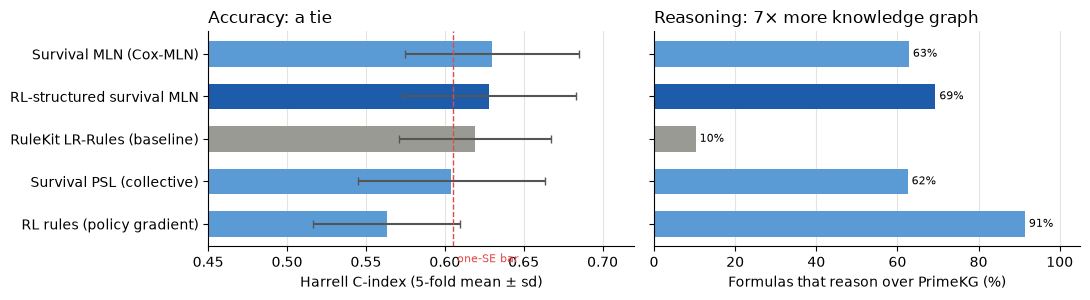

Engine: RL-structured survival MLN. Best by mean: mln (0.630); within one standard error: mln, rl_mln, rulekit


In [4]:
table = logic[['label', 'c_mean', 'c_std', 'uno_c_120', 'rules_per_fold', 'kg_rule_share']].copy()
table.columns = ['Reasoner', 'C-index (mean)', 'C-index (sd)', "Uno's C", 'Formulas per fold', 'Share using PrimeKG']
display(table.round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.1))
labels = logic.label.tolist()[::-1]
colors = [NAVY if l == engine['label'] else (GREY if 'RuleKit' in l else BLUE) for l in labels]
axes[0].barh(labels, logic.c_mean[::-1], xerr=logic.c_std[::-1], color=colors, height=0.6, error_kw={'ecolor': '#555', 'capsize': 3})
axes[0].axvline(engine['bar'], color=RED, linestyle='--', linewidth=1)
axes[0].text(engine['bar'], -0.9, ' one-SE bar', color=RED, fontsize=8)
axes[0].set_xlim(0.45, 0.72); axes[0].set_xlabel('Harrell C-index (5-fold mean ± sd)'); axes[0].set_title('Accuracy: a tie', loc='left')
axes[1].barh(labels, logic.kg_rule_share[::-1] * 100, color=colors, height=0.6)
for y, v in enumerate(logic.kg_rule_share[::-1] * 100):
    axes[1].text(v + 1, y, f'{v:.0f}%', va='center', fontsize=8)
axes[1].set_xlim(0, 105); axes[1].set_xlabel('Formulas that reason over PrimeKG (%)'); axes[1].set_title('Reasoning: 7× more knowledge graph', loc='left')
axes[1].set_yticklabels([])
for ax in axes: tidy(ax)
plt.tight_layout(); plt.show()
print(f"Engine: {engine['label']}. Best by mean: {engine['best']} ({engine['best_c']:.3f}); within one standard error: {', '.join(engine['eligible'])}")

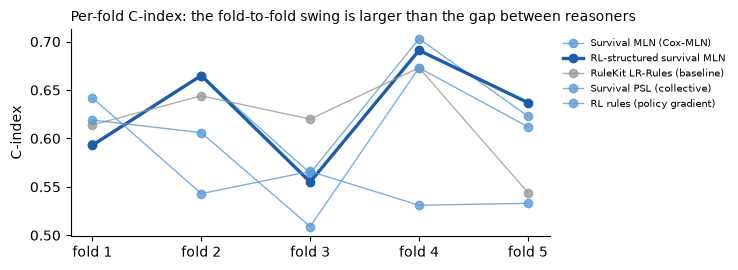

,Survival MLN (Cox-MLN),RL-structured survival MLN,RuleKit LR-Rules (baseline),Survival PSL (collective),RL rules (policy gradient)
fold 1,0.594,0.593,0.614,0.619,0.642
fold 2,0.665,0.665,0.644,0.606,0.543
fold 3,0.564,0.555,0.620,0.509,0.566
fold 4,0.703,0.691,0.673,0.673,0.531
fold 5,0.623,0.637,0.544,0.612,0.533


In [5]:
folds = pd.DataFrame({row.label: [float(x) for x in row.c_folds.split()] for row in logic.itertuples()}, index=[f'fold {k}' for k in range(1, 6)])
fig, ax = plt.subplots(figsize=(7.5, 2.8))
for label in folds.columns:
    style = dict(color=NAVY, linewidth=2.4) if label == engine['label'] else dict(color=GREY if 'RuleKit' in label else BLUE, linewidth=1, alpha=0.8)
    ax.plot(folds.index, folds[label], marker='o', label=label, **style)
ax.set_ylabel('C-index'); ax.set_title('Per-fold C-index: the fold-to-fold swing is larger than the gap between reasoners', loc='left', fontsize=10)
ax.legend(fontsize=7, frameon=False, bbox_to_anchor=(1.01, 1), loc='upper left'); ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.show()
display(folds.round(3))

**Reading the result honestly.**

* **Markov logic is ahead, but within noise.** Both MLN variants (about 0.63) lead RuleKit (0.62), PSL (0.60), and RL
  alone (0.56). The gap to RuleKit is smaller than the fold-to-fold swing, so MLN, RL-structured MLN, and RuleKit are
  statistically tied (the one-standard-error rule).
* **Among the tied reasoners we pick the richest one.** The preference order is RL-structured MLN > MLN > PSL > RL >
  RuleKit, so the engine is the **RL-structured MLN**.
* **The real gain is in what the rules can say**, shown in the next section.

## 5. The novelty, point by point

### 5.1 Weighted, combinable formulas instead of crisp rules

source,mined,rl,unary,total
fold 1,23,16,19,58
fold 2,11,0,9,20
fold 3,16,9,8,33
fold 4,9,5,2,16
fold 5,22,14,13,49


RuleKit kept 7.8 rules per fold; the engine kept 35.2 weighted formulas per fold.
Engine formulas over all folds: 176 = 81 mined, 51 unary, 44 rl


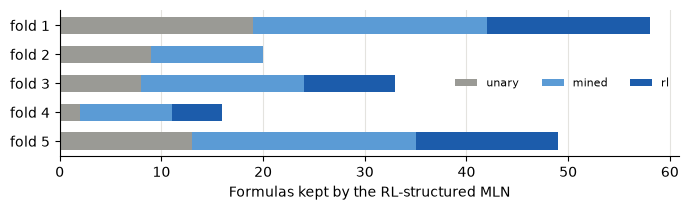

In [6]:
w = weights['rl_mln']
per_fold = w.groupby('fold').source.value_counts().unstack().fillna(0).astype(int)
per_fold.index = [f'fold {k + 1}' for k in per_fold.index]
display(per_fold.assign(total=per_fold.sum(axis=1)))
rk = rulekit.groupby('fold').size()
print(f"RuleKit kept {rk.mean():.1f} rules per fold; the engine kept {len(w) / 5:.1f} weighted formulas per fold.")
print(f"Engine formulas over all folds: {len(w)} = {', '.join(f'{v} {k}' for k, v in w.source.value_counts().items())}")
fig, ax = plt.subplots(figsize=(7, 2.2))
left = np.zeros(len(per_fold))
for source, color in [('unary', GREY), ('mined', BLUE), ('rl', NAVY)]:
    if source in per_fold:
        ax.barh(per_fold.index, per_fold[source], left=left, color=color, label=source, height=0.6)
        left += per_fold[source].to_numpy()
ax.invert_yaxis(); ax.set_xlabel('Formulas kept by the RL-structured MLN'); ax.legend(frameon=False, fontsize=8, ncol=3)
tidy(ax); plt.tight_layout(); plt.show()

### 5.2 Multi-hop knowledge-graph reasoning

The strongest RL-proposed formulas chain several PrimeKG relations, something RuleKit's single-condition tests on
predicates could not express.

In [7]:
rl_rows = w[w.source == 'rl'].sort_values('weight_per_sd', key=abs, ascending=False)
display(rl_rows[['fold', 'formula', 'weight_per_sd', 'support']].head(6).round(3))
mined = w[w.source == 'mined'].sort_values('weight_per_sd', key=abs, ascending=False)
display(Markdown('**Strongest mined clinical × PrimeKG formulas**'))
display(mined[['fold', 'formula', 'weight_per_sd', 'support']].head(4).round(3))

,fold,formula,weight_per_sd,support
1,0,"Altered(p, g) ∧ InPathway(g, 'VEGFA-VEGFR2 Pathway') ∧ Altered(p, g) ∧ InPathway(g, 'Ion homeostasis') ⇒ Progress(p)",-0.141,93
111,3,"Altered(p, g) ∧ InPathway(g, 'Neurofascin interactions') ∧ Altered(p, g) ∧ InPathway(g, 'Metalloprotease DUBs') ∧ Altered(p, g) ∧ InPathway(g, 'Es...",0.102,36
5,0,"Altered(p, g) ∧ InPathway(g, 'Stimuli-sensing channels') ∧ Altered(p, g) ∧ InPathway(g, 'Pyroptosis') ∧ Altered(p, g) ∧ TargetedBy(g, 'Flecainide'...",-0.097,70
132,4,"Radiation(p, no) ∧ Altered(p, g) ∧ InPathway(g, 'Platelet degranulation ') ∧ Altered(p, g) ∧ InPathway(g, 'TP53 Regulates Transcription of DNA Rep...",0.091,84
6,0,"Altered(p, g) ∧ InPathway(g, 'Keratan sulfate biosynthesis') ∧ Altered(p, g) ∧ InPathway(g, 'PKMTs methylate histone lysines') ∧ Altered(p, g) ∧ I...",-0.091,45
9,0,"Altered(p, g) ∧ InPathway(g, 'Signaling by activated point mutants of FGFR1') ∧ Altered(p, g) ∧ InPathway(g, 'Striated Muscle Contraction') ∧ Alte...",0.085,37


**Strongest mined clinical × PrimeKG formulas**

,fold,formula,weight_per_sd,support
79,2,"NStage(p, N3) ∧ Altered(p, g) ∧ LinkedTo(g, 'breast ductal adenocarcinoma') ⇒ Progress(p)",0.154,43
128,4,"TStage(p, T1) ∧ Subtype(p, LumA) ⇒ Progress(p)",-0.125,120
81,2,"Subtype(p, Her2) ∧ Altered(p, g) ∧ InPathway(g, 'Platelet degranulation ') ⇒ Progress(p)",0.103,32
4,0,"NStage(p, N1) ∧ Altered(p, g) ∧ InPathway(g, 'Clathrin-mediated endocytosis') ⇒ Progress(p)",-0.101,48


### 5.3 Do the formulas mean something? A Kaplan-Meier check

For the strongest RL-proposed formula, compare the patients for whom it holds against everyone else. The weight was
learned on four folds; the curve below uses the whole cohort, so read it as an illustration, not a test.

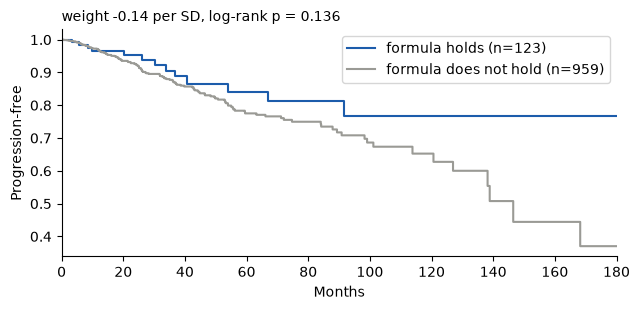

Altered(p, g) ∧ InPathway(g, 'VEGFA-VEGFR2 Pathway') ∧ Altered(p, g) ∧ InPathway(g, 'Ion homeostasis') ⇒ Progress(p)


In [8]:
from lifelines import KaplanMeierFitter
from lifelines.statistics import logrank_test
top = rl_rows.iloc[0]
holds = np.ones(len(order), dtype=bool)
for name in top.atoms.split('|'):
    holds &= values[:, atoms.atom.tolist().index(name)] > 0
t, e = outcome.time.to_numpy(float), outcome.event.to_numpy(int)
ok = np.isfinite(t)
fig, ax = plt.subplots(figsize=(6.5, 3.2))
for mask, label, color in [(holds & ok, f'formula holds (n={int((holds & ok).sum())})', NAVY), (~holds & ok, f'formula does not hold (n={int((~holds & ok).sum())})', GREY)]:
    KaplanMeierFitter().fit(t[mask], e[mask], label=label).plot_survival_function(ax=ax, ci_show=False, color=color)
test = logrank_test(t[holds & ok], t[~holds & ok], e[holds & ok], e[~holds & ok])
ax.set_xlabel('Months'); ax.set_ylabel('Progression-free'); ax.set_xlim(0, 180)
ax.set_title(f'weight {top.weight_per_sd:+.2f} per SD, log-rank p = {test.p_value:.3f}', loc='left', fontsize=10)
ax.spines[['top', 'right']].set_visible(False); plt.tight_layout(); plt.show()
print(top.formula)

### 5.4 Censoring handled correctly

A patient who has not relapsed *yet* is not a patient who never relapses. Both MLN variants learn their weights with
the Cox partial likelihood, and PSL uses Kaplan-Meier soft targets: a patient censored at 20 months gets the
probability that they progress before 36 months given that they were still progression-free at 20.

In [9]:
from src.neurosymbolic.logic.atoms import soft_targets
soft = soft_targets(outcome.time.to_numpy(float), outcome.event.to_numpy(int), np.arange(len(order)))
finite = np.isfinite(outcome.time)
censored_early = finite & (outcome.event == 0) & (outcome.time < 36)
print(f"{int(censored_early.sum())} patients were censored before 36 months; their soft targets range "
      f"{soft[censored_early].min():.2f}–{soft[censored_early].max():.2f} (median {np.median(soft[censored_early]):.2f}).")
print('A binary label would have called every one of them a non-progressor (0).')

584 patients were censored before 36 months; their soft targets range 0.00–0.12 (median 0.08).
A binary label would have called every one of them a non-progressor (0).


### 5.5 Two negative results that are worth reporting

* **PSL's collective rule found no signal.** Its learned weight is about 0.01 in every fold. A patient's similar
  neighbours add no outcome information beyond the patient's own facts.
* **RL alone overfits its search.** The policy sampled 20,000–27,000 distinct rules per fold. The best training rewards
  are partly luck (multiple testing), which is why RL alone scores 0.56. RL is useful as the *proposer* for the MLN,
  where the survival likelihood and the L1 penalty decide which proposals actually count.

In [10]:
psl_info = pd.DataFrame(engine['infos']['psl'])
psl_info.index = [f'fold {k}' for k in range(1, 6)]
display(psl_info[['collective_plus', 'collective_minus', 'prior']].round(3).rename(columns={'collective_plus': 'Similar ∧ HighRisk ⇒ HighRisk', 'collective_minus': 'Similar ∧ ¬HighRisk ⇒ ¬HighRisk'}))
rl_info = pd.DataFrame(engine['infos']['rl_mln'])
rl_info.index = [f'fold {k}' for k in range(1, 6)]
display(rl_info[['episodes', 'distinct_rules', 'rules', 'selected']].rename(columns={'rules': 'replicated on held-out 30%', 'selected': 'formulas with non-zero MLN weight'}))

,Similar ∧ HighRisk ⇒ HighRisk,Similar ∧ ¬HighRisk ⇒ ¬HighRisk,prior
fold 1,0.009,0.030,0.194
fold 2,0.005,0.018,0.141
fold 3,0.011,0.060,0.122
fold 4,0.011,0.060,0.027
fold 5,0.009,0.026,0.098


,episodes,distinct_rules,replicated on held-out 30%,formulas with non-zero MLN weight
fold 1,40960,21651,77,58
fold 2,40960,24642,8,20
fold 3,40960,19764,60,33
fold 4,40960,26525,150,16
fold 5,40960,25925,87,49


## 6. The best survival model overall

The logic engine is one input. The final risk in the reports comes from a **fused Cox model**: the clinical block plus
the GNN risk plus the logic-engine risk. All models were scored on the same folds.

,model,harrell_c_fold_mean,harrell_c_fold_std,uno_c_120,integrated_brier_120
0,Clinical Cox (19 fields),0.675,0.035,0.616,0.134
1,Clinical Cox (extended),0.667,0.042,0.657,0.135
2,Neuro-symbolic Cox (clinical + GNN + logic),0.664,0.021,0.616,0.134
3,Neuro-symbolic Cox (extended),0.662,0.042,0.655,0.135
4,"GNN + logic, no clinical",0.642,0.056,0.606,0.139
5,Survival MLN,0.630,0.055,0.617,NaN
6,RL-structured MLN,0.628,0.055,0.615,NaN
7,GraphSAGE (C-index loss),0.622,0.067,0.573,NaN
8,RuleKit,0.619,0.048,0.623,NaN
9,GCN (Cox),0.612,0.044,0.549,NaN


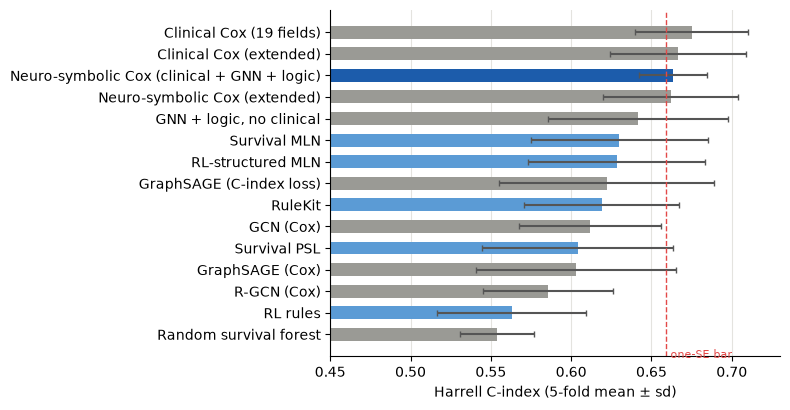

Best: clinical_cox_19 0.675; one standard error 0.016; bar 0.659
Statistically tied with the best: clinical_cox_19, clinical_cox_extended, neurosymbolic_cox, neurosymbolic_cox_extended
Report model: neurosymbolic_cox


In [11]:
timing = json.loads((OUT / 'fusion' / 'timing_evaluation.json').read_text())
metrics = pd.read_csv(OUT / 'fusion' / 'metrics.csv')
names = {'clinical_cox_19': 'Clinical Cox (19 fields)', 'clinical_cox_extended': 'Clinical Cox (extended)',
         'neurosymbolic_cox': 'Neuro-symbolic Cox (clinical + GNN + logic)', 'neurosymbolic_cox_extended': 'Neuro-symbolic Cox (extended)',
         'neural_symbolic_only': 'GNN + logic, no clinical', 'logic_mln': 'Survival MLN', 'logic_rl_mln': 'RL-structured MLN',
         'gnn_graphsage_cindex': 'GraphSAGE (C-index loss)', 'rulekit': 'RuleKit', 'gnn_gcn_cox': 'GCN (Cox)', 'logic_psl': 'Survival PSL',
         'gnn_graphsage_cox': 'GraphSAGE (Cox)', 'gnn_rgcn_cox': 'R-GCN (Cox)', 'logic_rl': 'RL rules', 'random_survival_forest': 'Random survival forest'}
view = metrics.assign(model=metrics.model.map(names).fillna(metrics.model))[['model', 'harrell_c_fold_mean', 'harrell_c_fold_std', 'uno_c_120', 'integrated_brier_120']]
display(view.round(3))
sel = timing['selection']
fig, ax = plt.subplots(figsize=(8, 4.2))
order_m = view.sort_values('harrell_c_fold_mean')
colors = [NAVY if m.startswith('Neuro-symbolic Cox (clinical') else (BLUE if m.startswith(('Survival MLN', 'RL-structured', 'Survival PSL', 'RL rules', 'RuleKit')) else GREY) for m in order_m.model]
ax.barh(order_m.model, order_m.harrell_c_fold_mean, xerr=order_m.harrell_c_fold_std, color=colors, height=0.6, error_kw={'ecolor': '#555', 'capsize': 2})
ax.axvline(sel['bar'], color=RED, linestyle='--', linewidth=1); ax.text(sel['bar'], -1.1, ' one-SE bar', color=RED, fontsize=8)
ax.set_xlim(0.45, 0.73); ax.set_xlabel('Harrell C-index (5-fold mean ± sd)'); tidy(ax); plt.tight_layout(); plt.show()
print(f"Best: {sel['best_model']} {sel['best_c']:.3f}; one standard error {sel['standard_error']:.3f}; bar {sel['bar']:.3f}")
print('Statistically tied with the best:', ', '.join(sel['eligible']))
print('Report model:', timing['report_model'])

**Why the neuro-symbolic Cox model is "the best" for this project.** Four models sit within one standard error of the
best clinical Cox model (0.675). They are tied. Among tied models we choose the one whose prediction can be
*explained* through knowledge-graph paths and logic formulas, the neuro-symbolic Cox model (0.664). It costs nothing
measurable in accuracy and is the only tied model that can say *why*.

Every model family (GNN, logic, forest, Cox) stops near a C-index of 0.67. With 145 progressions, nodal stage, stage,
age, and subtype carry most of the signal. The neuro-symbolic layer adds **explanation, not extra accuracy**, and we say
so in the thesis and in every report.

## 7. The mentor's path score: 0.6 × neural + 0.4 × rule

Each explanation path in a report is a real walk in the patient's fused graph: patient → sample → altered gene →
(protein partner) → pathway / drug / breast disease.

* **neural** = how much the GNN relied on the path's edges (GNNExplainer importance, as a cohort percentile);
* **rule** = the summed weight of the engine's formulas that the path *grounds*: formulas that hold for this patient
  and mention the path's end node, its altered gene, or a gene on the path. It is scaled to 0–1, and its sign gives
  the direction;
* **score** = 0.6 × neural + 0.4 × rule. The top 20% of scores are "prominent", and a report shows
  min(5, prominent) paths with at least 3.

59598 candidate paths; prominence cutoff = 0.523
Paths that ground at least one learned formula: 27.5% of candidates, 34.6% of the paths shown in reports


**Example: TCGA-BH-A1EV**, group A, recorded progression at 12.0 months

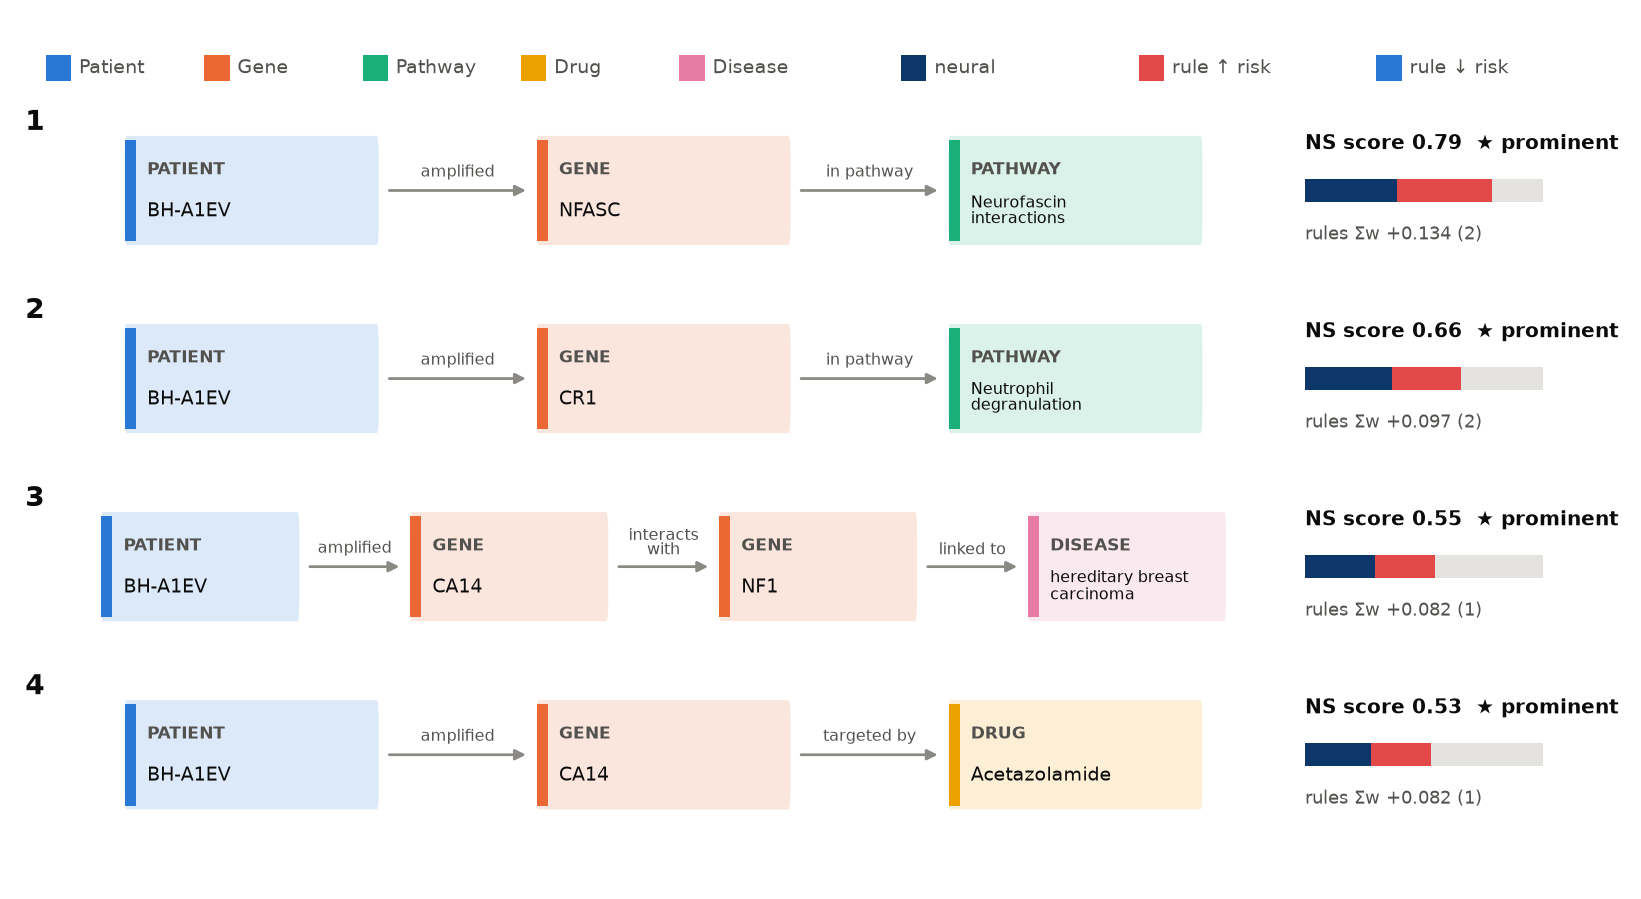

,rank,altered_gene,terminal_name,neural,rule_score,rule_count,ns_score,prominent
0,1,NFASC,Neurofascin interactions,0.642,0.134,2,0.785,True
1,2,CR1,Neutrophil degranulation,0.607,0.097,2,0.657,True
2,3,CA14,hereditary breast carcinoma,0.493,0.082,1,0.545,True
3,4,CA14,Acetazolamide,0.465,0.082,1,0.529,True


In [12]:
from src.neurosymbolic.report_pdf import load_context
from src.neurosymbolic import report_figures as F
ctx = load_context(OUT)
scored = ctx.scored_paths
shown = pd.concat([ctx.paths_for(pid) for pid in ctx.patient_ids if len(ctx.paths_for(pid))])
print(f"{len(scored)} candidate paths; prominence cutoff = {ctx.cutoff:.3f}")
print(f"Paths that ground at least one learned formula: {(scored.rule_count > 0).mean():.1%} of candidates, {(shown.rule_count > 0).mean():.1%} of the paths shown in reports")
pid = 'TCGA-BH-A1EV'
paths = ctx.paths_for(pid)
display(Markdown(f"**Example: {pid}**, group A, recorded progression at {pred.set_index('patient_id').loc[pid, 'time']:.1f} months"))
display(Image(F.path_figure(paths.to_dict('records'))))
display(paths[['rank', 'altered_gene', 'terminal_name', 'neural', 'rule_score', 'rule_count', 'ns_score', 'prominent']].round(3))

## 8. What it looks like in a report

Page 2 of the example patient's report: the top-K paths with their neural/rule split, and the weighted logic formulas
that fire for this patient.

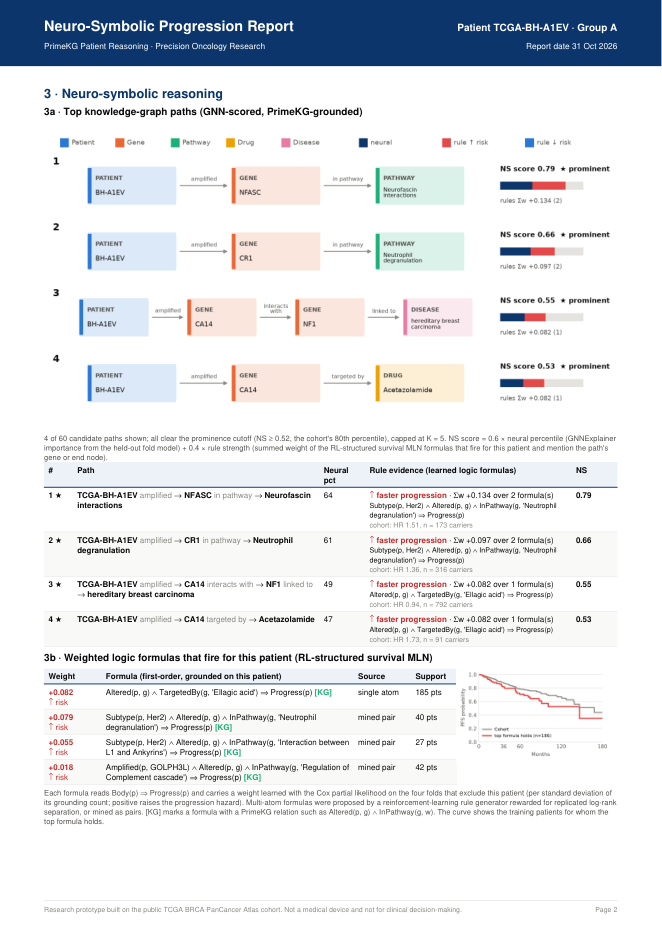

In [13]:
import pymupdf
doc = pymupdf.open(REPORTS / 'A_progression_within_12m' / 'TCGA-BH-A1EV.pdf')
page = min(1, doc.page_count - 1)
display(Image(doc[page].get_pixmap(dpi=80).tobytes('png')))

## 9. Novelty checklist for the presentation

| Claim | Evidence in this notebook |
| --- | --- |
| Symbolic reasoning moved from crisp IF-THEN rules to **weighted first-order logic** | section 1, about 35 weighted formulas per fold against about 8 rules |
| **Survival-aware Markov logic**: formula weights learned with the Cox partial likelihood, so censoring is handled correctly | sections 3 and 5.4 |
| **Reinforcement learning as the MLN's structure learner**, with a replication reward against multiple testing | sections 3, 5.2, and 5.5 |
| **Multi-hop PrimeKG formulas**: 69% of the engine's formulas use the knowledge graph against 10% for RuleKit | sections 4 and 5.2 |
| All three of the mentor's methods were tried, and the comparison is honest, negative results included | sections 4 and 5.5 |
| Path score follows the mentor's **0.6 × neural + 0.4 × rule** | section 7 |
| Accuracy is unchanged: about 0.63 for logic and 0.664 for the fused model, tied with clinical Cox | sections 4 and 6 |

Reproduce with:

```bash
python scripts/run_neurosymbolic_pipeline.py --stages logic,fusion,explain
python scripts/build_patient_reports.py --workers 4
python scripts/build_logic_novelty_notebook.py --kernel primekg-ns
```